# E-commerce Sales Analysis with Python

## Project Overview

This project analyzes an e-commerce dataset containing 2,000 orders from January 2023 to December 2025.

The goal is to explore sales performance, profitability, customer segments, product categories, geographic trends, and the relationship between discounts and profit margins.

## Tools and Technologies

- Python
- Pandas
- Matplotlib
- Google Colab

In [1]:

import pandas as pd

print("Pandas är redo!")


Pandas är redo!


## 1. Data Loading

In this section, I load the e-commerce dataset into a Pandas DataFrame and prepare the order date column for analysis.

In [2]:

import pandas as pd

# Kontrollera vilken version av pandas vi använder
print("Pandas version:", pd.__version__)


Pandas version: 2.2.3


In [3]:

import pandas as pd

df = pd.read_csv(
    "/content/global_ecommerce_sales.csv",
    parse_dates=["Order_Date"]
)

print("Antal rader:", len(df))
print("Antal kolumner:", len(df.columns))

df.head()


Antal rader: 2000
Antal kolumner: 15


,Order_ID,Order_Date,Customer_Name,Customer_Segment,Country,Region,Product_Category,Product_Name,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit,Payment_Method
0,ORD-11121,2023-01-02,Karen Suzuki,Corporate,United States,North America,Technology,Wireless Bluetooth Headphones,3,99.43,0,298.29,9.31,124.92,Cash on Delivery
1,ORD-11244,2023-01-02,John Johansson,Corporate,Spain,Europe,Technology,Mechanical Gaming Keyboard,4,97.93,20,313.38,14.31,83.62,Cash on Delivery
2,ORD-10325,2023-01-03,Jessica Garcia,Consumer,Mexico,North America,Office Supplies,Binder Clips Assorted 48pc,2,10.74,0,21.48,8.12,3.69,Credit Card
3,ORD-10467,2023-01-03,Clara Taylor,Corporate,Italy,Europe,Technology,Webcam HD 1080p,2,61.86,15,105.16,10.79,26.32,PayPal
4,ORD-11454,2023-01-05,Felix Thomas,Consumer,Italy,Europe,Furniture,Standing Desk Converter,4,330.67,20,1058.14,11.09,253.44,Credit Card


In [4]:

# Visa information om kolumner och datatyper
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order_ID          2000 non-null   object        
 1   Order_Date        2000 non-null   datetime64[ns]
 2   Customer_Name     2000 non-null   object        
 3   Customer_Segment  2000 non-null   object        
 4   Country           2000 non-null   object        
 5   Region            2000 non-null   object        
 6   Product_Category  2000 non-null   object        
 7   Product_Name      2000 non-null   object        
 8   Quantity          2000 non-null   int64         
 9   Unit_Price        2000 non-null   float64       
 10  Discount_Percent  2000 non-null   int64         
 11  Total_Sales       2000 non-null   float64       
 12  Shipping_Cost     2000 non-null   float64       
 13  Profit            2000 non-null   float64       
 14  Payment_Method    2000 n

## 3. Data Quality Checks

Before analyzing sales performance, I checked the dataset for missing values, duplicate rows, duplicate order IDs, inconsistent categories, and potential discrepancies in sales calculations.

These checks help identify data quality issues that could affect the analysis and interpretation of the results.

In [5]:

# Kontrollera helt identiska rader
duplicates = df.duplicated().sum()

print("Antal helt identiska dubblettrader:", duplicates)


Antal helt identiska dubblettrader: 0


In [6]:

# Kontrollera antal unika order-ID:n
unique_orders = df["Order_ID"].nunique()

print("Antal rader:", len(df))
print("Antal unika order-ID:n:", unique_orders)
print("Order-ID:n som förekommer på flera rader:",
      df["Order_ID"].duplicated().sum())


Antal rader: 2000
Antal unika order-ID:n: 2000
Order-ID:n som förekommer på flera rader: 0


In [7]:

# Kontrollera minsta och största värdet i numeriska kolumner
df[[
    "Quantity",
    "Unit_Price",
    "Discount_Percent",
    "Total_Sales",
    "Shipping_Cost",
    "Profit"
]].describe()


,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000
mean,3.557500,73.329490,8.572500,242.279670,12.90212,79.436160
std,2.704506,79.311014,7.261274,382.583802,5.22319,137.573593
min,1.000000,3.030000,0.000000,2.420000,5.52000,-11.280000
25%,2.000000,18.757500,0.000000,41.227500,9.45750,6.865000
50%,3.000000,46.420000,10.000000,113.125000,11.84500,32.830000
75%,5.000000,90.250000,15.000000,266.552500,14.92000,90.297500
max,15.000000,472.560000,30.000000,3813.980000,40.44000,1373.630000


In [8]:

# Filtrera fram rader där vinsten är negativ
loss_orders = df[df["Profit"] < 0]

print("Antal poster med negativ vinst:", len(loss_orders))

loss_orders[[
    "Order_ID",
    "Product_Name",
    "Quantity",
    "Unit_Price",
    "Discount_Percent",
    "Total_Sales",
    "Profit"
]]


Antal poster med negativ vinst: 272


,Order_ID,Product_Name,Quantity,Unit_Price,Discount_Percent,Total_Sales,Profit
11,ORD-11499,Paper Clips Box 500pc,3,7.80,10,21.06,-2.08
14,ORD-10793,Tape Dispenser Heavy Duty,1,15.82,0,15.82,-0.46
20,ORD-10686,Whiteboard Markers Set 8,5,9.91,25,37.16,-5.87
23,ORD-10846,Sticky Notes Multicolor 6-Pack,2,11.41,5,21.68,-3.85
31,ORD-11723,Stapler Full-Size,1,8.54,15,7.26,-4.55
...,...,...,...,...,...,...,...
1954,ORD-10352,Tape Dispenser Heavy Duty,2,13.26,10,23.87,-3.28
1967,ORD-11898,Sticky Notes Multicolor 6-Pack,1,9.32,0,9.32,-1.10
1968,ORD-10723,Paper Clips Box 500pc,4,6.29,10,22.64,-2.84
1982,ORD-11286,Ballpoint Pen Pack 12,2,9.45,15,16.06,-1.76


In [9]:

# Beräkna förväntad försäljning utifrån antal, pris och rabatt
df["Expected_Sales"] = (
    df["Quantity"]
    * df["Unit_Price"]
    * (1 - df["Discount_Percent"] / 100)
).round(2)

# Jämför beräknad försäljning med det registrerade beloppet
df["Sales_Difference"] = (
    df["Total_Sales"] - df["Expected_Sales"]
).round(2)

# Räkna poster där beloppen skiljer sig
mismatches = df[df["Sales_Difference"] != 0]

print("Antal poster med avvikande försäljningsbelopp:", len(mismatches))

mismatches[[
    "Order_ID",
    "Quantity",
    "Unit_Price",
    "Discount_Percent",
    "Total_Sales",
    "Expected_Sales",
    "Sales_Difference"
]].head(10)


Antal poster med avvikande försäljningsbelopp: 31


,Order_ID,Quantity,Unit_Price,Discount_Percent,Total_Sales,Expected_Sales,Sales_Difference
24,ORD-11128,5,333.59,10,1501.15,1501.16,-0.01
72,ORD-10473,2,143.15,5,271.99,271.98,0.01
111,ORD-10124,5,11.95,10,53.77,53.78,-0.01
122,ORD-10070,5,149.77,10,673.97,673.96,0.01
227,ORD-11394,1,217.82,25,163.37,163.36,0.01
285,ORD-10674,10,14.57,5,138.41,138.42,-0.01
299,ORD-10792,5,18.79,10,84.55,84.56,-0.01
323,ORD-10961,1,61.50,15,52.27,52.28,-0.01
331,ORD-10904,1,190.35,10,171.31,171.32,-0.01
393,ORD-10917,2,12.61,25,18.91,18.92,-0.01


In [10]:

# Undersök hur stora avvikelserna är
print("Största absoluta avvikelsen:",
      df["Sales_Difference"].abs().max())

print("\nFördelning av avvikelser:")
print(df["Sales_Difference"].value_counts().sort_index())


Största absoluta avvikelsen: 0.01

Fördelning av avvikelser:
Sales_Difference
-0.01      20
 0.00    1969
 0.01      11
Name: count, dtype: int64


In [11]:

# Räkna saknade värden i varje kolumn
missing_values = df.isnull().sum()

print("Saknade värden per kolumn:")
print(missing_values)

print("\nTotalt antal saknade värden:",
      missing_values.sum())


Saknade värden per kolumn:
Order_ID            0
Order_Date          0
Customer_Name       0
Customer_Segment    0
Country             0
Region              0
Product_Category    0
Product_Name        0
Quantity            0
Unit_Price          0
Discount_Percent    0
Total_Sales         0
Shipping_Cost       0
Profit              0
Payment_Method      0
Expected_Sales      0
Sales_Difference    0
dtype: int64

Totalt antal saknade värden: 0


In [12]:

# Kontrollera vilka kategorier som finns i datan
print("Produktkategorier:")
print(df["Product_Category"].value_counts())

print("\nKundsegment:")
print(df["Customer_Segment"].value_counts())

print("\nBetalningsmetoder:")
print(df["Payment_Method"].value_counts())


Produktkategorier:
Product_Category
Technology                567
Office Supplies           513
Furniture                 507
Clothing & Accessories    413
Name: count, dtype: int64

Kundsegment:
Customer_Segment
Consumer       1006
Corporate       623
Home Office     371
Name: count, dtype: int64

Betalningsmetoder:
Payment_Method
Credit Card         797
PayPal              609
Cash on Delivery    301
Bank Transfer       293
Name: count, dtype: int64


In [13]:
print("Första orderdatum:", df["Order_Date"].min())
print("Sista orderdatum:", df["Order_Date"].max())

print("\nAntal olika orderdatum:", df["Order_Date"].nunique())

Första orderdatum: 2023-01-02 00:00:00
Sista orderdatum: 2025-12-31 00:00:00

Antal olika orderdatum: 907


## 4. Sales Analysis

In this section, I analyze sales performance over time and across product categories, countries, and months. The goal is to identify trends and understand which areas contribute most to total sales.

In [14]:

# Skapa en kolumn som innehåller året för varje order
df["Year"] = df["Order_Date"].dt.year

# Summera försäljningen per år
yearly_sales = df.groupby("Year")["Total_Sales"].sum()

print("Total försäljning per år:")
print(yearly_sales.round(2))


Total försäljning per år:
Year
2023    164443.45
2024    155150.73
2025    164965.16
Name: Total_Sales, dtype: float64


In [15]:

# Beräkna procentuell förändring från föregående år
yearly_change = yearly_sales.pct_change() * 100

print("Förändring i försäljning jämfört med föregående år:")
print(yearly_change.round(2))


Förändring i försäljning jämfört med föregående år:
Year
2023     NaN
2024   -5.65
2025    6.33
Name: Total_Sales, dtype: float64


In [16]:

# Summera vinsten per år
yearly_profit = df.groupby("Year")["Profit"].sum()

print("Total vinst per år:")
print(yearly_profit.round(2))


Total vinst per år:
Year
2023    53153.74
2024    51616.11
2025    54102.47
Name: Profit, dtype: float64


In [17]:

# Summera försäljning och vinst per år
yearly_summary = df.groupby("Year").agg(
    Total_Sales=("Total_Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

# Beräkna vinstmarginal i procent
yearly_summary["Profit_Margin_Percent"] = (
    yearly_summary["Total_Profit"]
    / yearly_summary["Total_Sales"]
    * 100
)

print(yearly_summary.round(2))


      Total_Sales  Total_Profit  Profit_Margin_Percent
Year                                                  
2023    164443.45      53153.74                  32.32
2024    155150.73      51616.11                  33.27
2025    164965.16      54102.47                  32.80


## 5. Customer and Product Analysis

In this section, I analyze sales and profitability across customer segments and individual products. The aim is to identify the strongest-performing segments and products that may require further investigation.

In [18]:

# Summera försäljningen per produktkategori
category_sales = (
    df.groupby("Product_Category")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Försäljning per produktkategori:")
print(category_sales.round(2))


Försäljning per produktkategori:
Product_Category
Furniture                 256274.68
Technology                139518.22
Clothing & Accessories     69375.63
Office Supplies            19390.81
Name: Total_Sales, dtype: float64


In [19]:

# Summera försäljning och vinst per produktkategori
category_summary = df.groupby("Product_Category").agg(
    Total_Sales=("Total_Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

# Beräkna vinstmarginal
category_summary["Profit_Margin_Percent"] = (
    category_summary["Total_Profit"]
    / category_summary["Total_Sales"]
    * 100
)

# Sortera efter total vinst, högst först
category_summary = category_summary.sort_values(
    by="Total_Profit",
    ascending=False
)

print(category_summary.round(2))


                        Total_Sales  Total_Profit  Profit_Margin_Percent
Product_Category                                                        
Furniture                 256274.68      81171.57                  31.67
Technology                139518.22      48268.65                  34.60
Clothing & Accessories     69375.63      26112.94                  37.64
Office Supplies            19390.81       3319.16                  17.12


In [20]:

# Summera försäljningen per land
country_sales = (
    df.groupby("Country")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Försäljning per land:")
print(country_sales.round(2))

print("\nAntal länder:", df["Country"].nunique())


Försäljning per land:
Country
Mexico            47217.30
Canada            45326.55
United States     41332.53
Japan             30950.19
United Kingdom    30185.46
Germany           28989.73
China             28322.85
Italy             27484.38
France            26616.81
Australia         25287.72
Spain             23729.82
South Korea       18745.21
Brazil            18473.97
India             18401.54
Argentina         17717.00
Saudi Arabia      13680.22
South Africa      13564.80
Nigeria            9899.91
Colombia           9860.16
UAE                8773.19
Name: Total_Sales, dtype: float64

Antal länder: 20


In [21]:

# Summera försäljning och vinst per land
country_summary = df.groupby("Country").agg(
    Total_Sales=("Total_Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

# Beräkna vinstmarginal per land
country_summary["Profit_Margin_Percent"] = (
    country_summary["Total_Profit"]
    / country_summary["Total_Sales"]
    * 100
)

# Sortera efter total försäljning
country_summary = country_summary.sort_values(
    by="Total_Sales",
    ascending=False
)

print(country_summary.round(2))


                Total_Sales  Total_Profit  Profit_Margin_Percent
Country                                                         
Mexico             47217.30      15949.44                  33.78
Canada             45326.55      15320.95                  33.80
United States      41332.53      13979.70                  33.82
Japan              30950.19       9826.31                  31.75
United Kingdom     30185.46      10185.32                  33.74
Germany            28989.73       9518.07                  32.83
China              28322.85       9028.07                  31.88
Italy              27484.38       9125.06                  33.20
France             26616.81       8973.46                  33.71
Australia          25287.72       8072.37                  31.92
Spain              23729.82       7870.25                  33.17
South Korea        18745.21       6124.07                  32.67
Brazil             18473.97       5869.63                  31.77
India              18401.

In [22]:

# Skapa en kolumn för månad
df["Month"] = df["Order_Date"].dt.month

# Summera försäljningen per kalendermånad
monthly_sales = (
    df.groupby("Month")["Total_Sales"]
    .sum()
    .reindex(range(1, 13), fill_value=0)
)

# Gör månadsnumren lättare att läsa
month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

monthly_sales.index = monthly_sales.index.map(month_names)

print("Total försäljning per kalendermånad, 2023–2025:")
print(monthly_sales.round(2))


Total försäljning per kalendermånad, 2023–2025:
Month
January      31611.59
February     36260.55
March        34378.89
April        44203.66
May          42434.47
June         43694.85
July         45671.22
August       34157.01
September    36002.05
October      51095.40
November     39669.78
December     45379.87
Name: Total_Sales, dtype: float64


In [23]:

# Skapa en tabell med försäljning per månad och år
monthly_yearly_sales = df.pivot_table(
    index="Month",
    columns="Year",
    values="Total_Sales",
    aggfunc="sum"
)

# Lägg till månadsnamn
monthly_yearly_sales.index = monthly_yearly_sales.index.map(
    month_names
)

print("Försäljning per månad och år:")
print(monthly_yearly_sales.round(2))


Försäljning per månad och år:
Year           2023      2024      2025
Month                                  
January    11275.20   8015.21  12321.18
February   16943.67  11979.60   7337.28
March      16056.45  10550.11   7772.33
April      12185.00  15615.06  16403.60
May         8218.47  16594.20  17621.80
June       16191.61   9435.15  18068.09
July       15667.73  14937.53  15065.96
August     12971.07   9883.83  11302.11
September  11989.72   9636.38  14375.95
October    17794.60  17426.05  15874.75
November    8475.49  16413.27  14781.02
December   16674.44  14664.34  14041.09


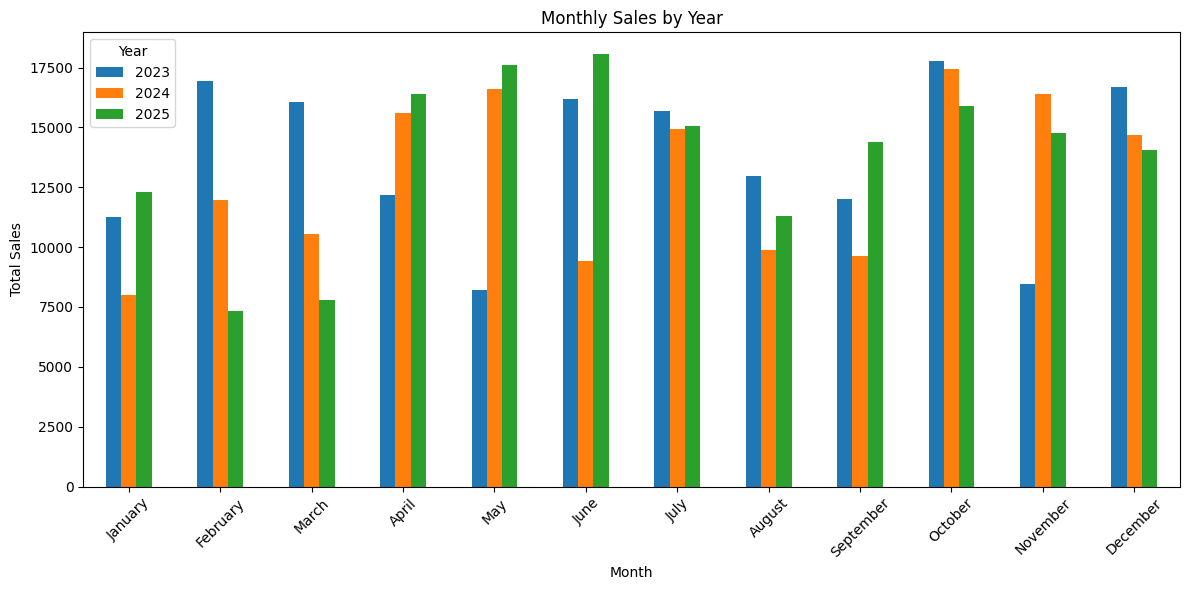

In [24]:

import matplotlib.pyplot as plt

monthly_yearly_sales.plot(kind="bar", figsize=(12, 6))

plt.title("Monthly Sales by Year")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.legend(title="Year")
plt.tight_layout()
plt.show()


In [25]:

# Summera försäljning och vinst per kundsegment
segment_summary = df.groupby("Customer_Segment").agg(
    Total_Sales=("Total_Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

# Beräkna vinstmarginal per kundsegment
segment_summary["Profit_Margin_Percent"] = (
    segment_summary["Total_Profit"]
    / segment_summary["Total_Sales"]
    * 100
)

# Sortera efter försäljning, högst först
segment_summary = segment_summary.sort_values(
    by="Total_Sales",
    ascending=False
)

print("Försäljning och vinst per kundsegment:")
print(segment_summary.round(2))


Försäljning och vinst per kundsegment:
                  Total_Sales  Total_Profit  Profit_Margin_Percent
Customer_Segment                                                  
Consumer            256287.74      87300.36                  34.06
Corporate           146050.39      44463.44                  30.44
Home Office          82221.21      27108.52                  32.97


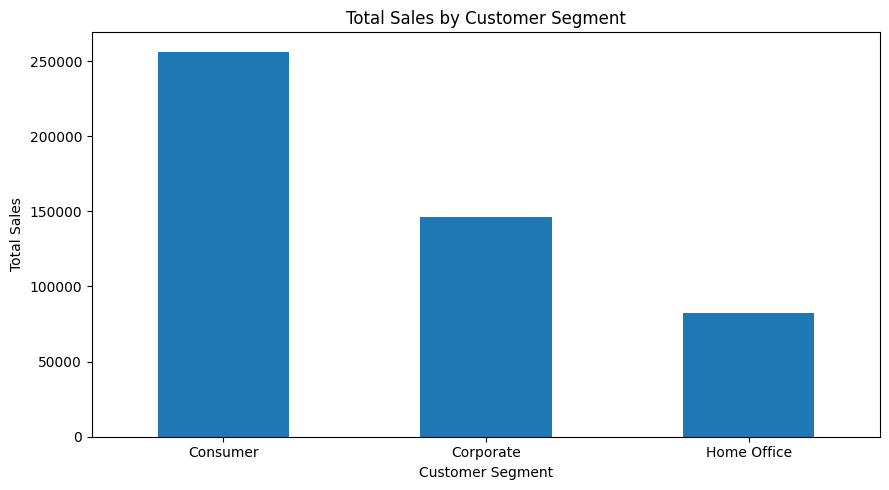

In [26]:

import matplotlib.pyplot as plt

segment_summary["Total_Sales"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [27]:

# Summera försäljning och vinst per betalningsmetod
payment_summary = df.groupby("Payment_Method").agg(
    Total_Sales=("Total_Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

# Beräkna vinstmarginal
payment_summary["Profit_Margin_Percent"] = (
    payment_summary["Total_Profit"]
    / payment_summary["Total_Sales"]
    * 100
)

# Sortera efter försäljning, högst först
payment_summary = payment_summary.sort_values(
    by="Total_Sales",
    ascending=False
)

print("Försäljning och vinst per betalningsmetod:")
print(payment_summary.round(2))


Försäljning och vinst per betalningsmetod:
                  Total_Sales  Total_Profit  Profit_Margin_Percent
Payment_Method                                                    
Credit Card         192717.89      62323.24                  32.34
PayPal              143112.87      47288.80                  33.04
Cash on Delivery     77129.54      25704.89                  33.33
Bank Transfer        71599.04      23555.39                  32.90


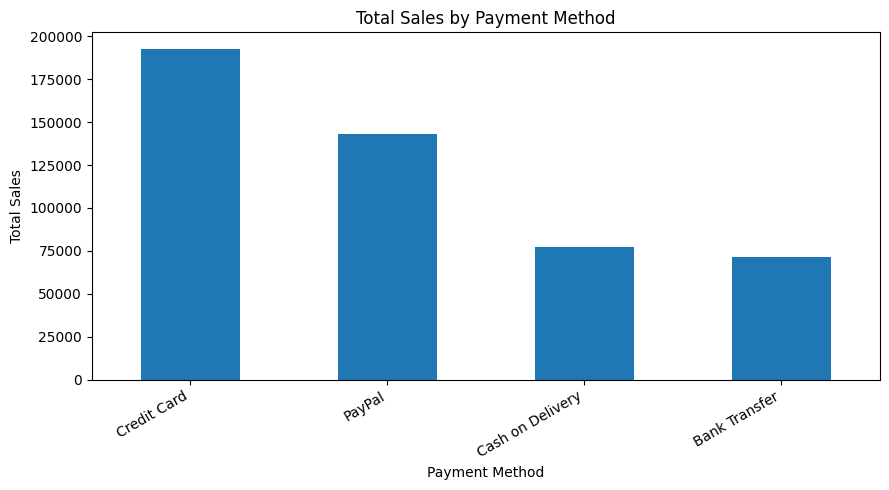

In [28]:

import matplotlib.pyplot as plt

payment_summary["Total_Sales"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Total Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 6. Discount and Profitability Analysis

In this section, I investigate how discount levels relate to sales, total profit, and profit margins. I also examine loss-making orders to identify product categories and discount levels that may require further investigation.

In [29]:

# Gruppera order efter rabattprocent
discount_summary = df.groupby("Discount_Percent").agg(
    Total_Sales=("Total_Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Number_of_Orders=("Order_ID", "count")
)

# Beräkna vinstmarginal i procent
discount_summary["Profit_Margin_Percent"] = (
    discount_summary["Total_Profit"]
    / discount_summary["Total_Sales"]
    * 100
)

print(discount_summary.round(2))


                  Total_Sales  Total_Profit  Number_of_Orders  \
Discount_Percent                                                
0                   130966.22      50705.28               503   
5                   130452.23      46129.15               488   
10                  103136.11      32932.51               443   
15                   61074.44      16503.10               312   
20                   40229.76       9305.38               169   
25                   13272.27       2568.58                67   
30                    5428.31        728.32                18   

                  Profit_Margin_Percent  
Discount_Percent                         
0                                 38.72  
5                                 35.36  
10                                31.93  
15                                27.02  
20                                23.13  
25                                19.35  
30                                13.42  


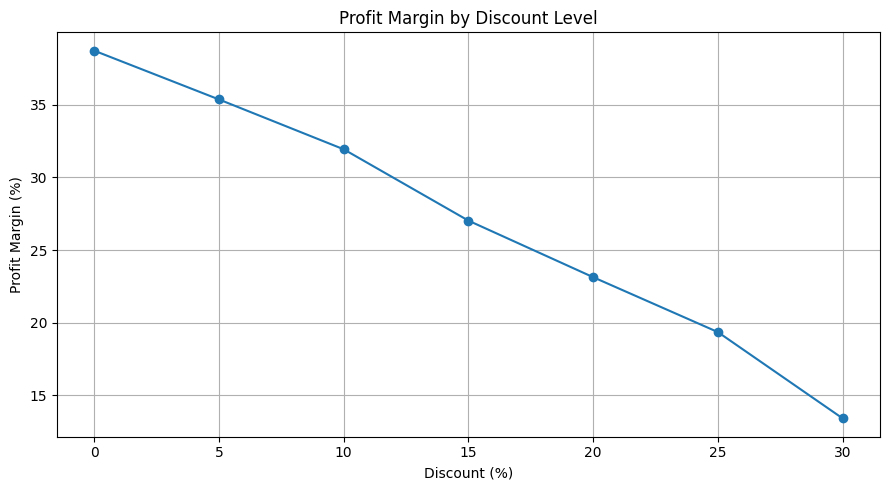

In [30]:

import matplotlib.pyplot as plt

discount_summary["Profit_Margin_Percent"].plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

plt.title("Profit Margin by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Profit Margin (%)")
plt.xticks(discount_summary.index)
plt.grid(True)
plt.tight_layout()
plt.show()


**Finding: Discounts and Profitability**

The analysis shows a clear negative relationship between discount levels and profit margins in the dataset. Profit margins declined from 38.72% at 0% discount to 13.42% at 30% discount. This represents a decrease of 25.30 percentage points.

Higher discount levels were also associated with fewer orders. Further analysis would be needed to determine whether discounts influence order volume and profitability or whether other factors explain these patterns.

In [31]:

# Räkna order med vinst, förlust och nollresultat
profitable_orders = (df["Profit"] > 0).sum()
loss_orders = (df["Profit"] < 0).sum()
break_even_orders = (df["Profit"] == 0).sum()

print("Orders with profit:", profitable_orders)
print("Orders with loss:", loss_orders)
print("Orders with zero profit:", break_even_orders)


Orders with profit: 1728
Orders with loss: 272
Orders with zero profit: 0


In [32]:

# Filtrera fram order med negativ vinst
loss_df = df[df["Profit"] < 0]

print("Number of loss-making orders:", len(loss_df))
print("Total loss:", round(loss_df["Profit"].sum(), 2))
print("Average loss per order:", round(loss_df["Profit"].mean(), 2))
print("Largest loss:", round(loss_df["Profit"].min(), 2))


Number of loss-making orders: 272
Total loss: -953.39
Average loss per order: -3.51
Largest loss: -11.28


In [33]:

# Filtrera fram order med negativ vinst
loss_df = df[df["Profit"] < 0]

# Sammanfatta förluster per produktkategori
category_losses = loss_df.groupby("Product_Category").agg(
    Number_of_Loss_Orders=("Order_ID", "count"),
    Total_Loss=("Profit", "sum")
)

# Sortera efter total förlust
category_losses = category_losses.sort_values(
    by="Total_Loss",
    ascending=True
)

print(category_losses.round(2))


                        Number_of_Loss_Orders  Total_Loss
Product_Category                                         
Office Supplies                           224     -827.99
Clothing & Accessories                     23      -56.00
Technology                                 15      -37.04
Furniture                                  10      -32.36


In [34]:

# Sammanfatta förlustorder per rabattnivå
loss_discount_summary = loss_df.groupby("Discount_Percent").agg(
    Number_of_Loss_Orders=("Order_ID", "count"),
    Total_Loss=("Profit", "sum")
)

print(loss_discount_summary.round(2))


                  Number_of_Loss_Orders  Total_Loss
Discount_Percent                                   
0                                    56     -165.38
5                                    49     -164.94
10                                   59     -223.53
15                                   65     -223.92
20                                   26     -117.43
25                                   15      -51.77
30                                    2       -6.42


In [35]:

# Räkna alla order vid varje rabattnivå
total_orders_by_discount = df.groupby("Discount_Percent")["Order_ID"].count()

# Räkna förlustorder vid varje rabattnivå
loss_orders_by_discount = loss_df.groupby("Discount_Percent")["Order_ID"].count()

# Beräkna andelen förlustorder i procent
loss_rate = (
    loss_orders_by_discount / total_orders_by_discount * 100
)

# Samla resultaten i en tabell
loss_rate_summary = pd.DataFrame({
    "Total_Orders": total_orders_by_discount,
    "Loss_Orders": loss_orders_by_discount,
    "Loss_Rate_Percent": loss_rate
})

print(loss_rate_summary.round(2))


                  Total_Orders  Loss_Orders  Loss_Rate_Percent
Discount_Percent                                              
0                          503           56              11.13
5                          488           49              10.04
10                         443           59              13.32
15                         312           65              20.83
20                         169           26              15.38
25                          67           15              22.39
30                          18            2              11.11


In [36]:

# Filtrera fram Office Supplies
office_supplies = df[
    df["Product_Category"] == "Office Supplies"
]

# Sammanfatta försäljning och vinst per rabattnivå
office_discount_summary = office_supplies.groupby(
    "Discount_Percent"
).agg(
    Total_Orders=("Order_ID", "count"),
    Total_Profit=("Profit", "sum")
)

# Beräkna vinstmarginal
office_discount_summary["Profit_Margin_Percent"] = (
    office_discount_summary["Total_Profit"]
    / office_supplies.groupby("Discount_Percent")["Total_Sales"].sum()
    * 100
)

print(office_discount_summary.round(2))


                  Total_Orders  Total_Profit  Profit_Margin_Percent
Discount_Percent                                                   
0                          126       1244.91                  24.38
5                          120        911.44                  19.47
10                         114        669.20                  16.28
15                         100        375.09                  10.65
20                          34        121.25                   8.89
25                          16          0.17                   0.03
30                           3         -2.90                  -2.68


### Finding: Discount Levels and Office Supplies Profitability

The analysis of the Office Supplies category shows a clear decline in profit margin as discount levels increase. The profit margin decreased from 24.38% with no discount to -2.68% at a 30% discount.

At a 25% discount, the category generated almost no profit, with a total profit of only 0.17. At a 30% discount, the three orders generated a combined loss of 2.90.

These findings suggest that high discount levels are associated with lower profitability in the Office Supplies category. However, the small number of orders at the highest discount levels means that further analysis is needed before drawing firm conclusions about the impact of discounts.

In [37]:

# Sammanfatta försäljning och vinst per produkt
product_summary = df.groupby("Product_Name").agg(
    Total_Sales=("Total_Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Number_of_Orders=("Order_ID", "count")
)

# Sortera så att produkterna med lägst vinst visas först
product_summary = product_summary.sort_values(
    by="Total_Profit",
    ascending=True
)

# Visa de 10 produkter som har lägst total vinst
print("10 products with the lowest total profit:")
print(product_summary.head(10).round(2))


10 products with the lowest total profit:
                                Total_Sales  Total_Profit  Number_of_Orders
Product_Name                                                               
Paper Clips Box 500pc                901.89        -79.95                45
Highlighters Neon Pack 6             942.61         -0.37                39
Sticky Notes Multicolor 6-Pack      1072.27         61.90                39
Binder Clips Assorted 48pc          1924.59        214.49                58
Ballpoint Pen Pack 12               1760.36        254.45                50
Whiteboard Markers Set 8            2090.67        311.95                59
Desk Calendar 2025                  2481.21        489.92                59
Stapler Full-Size                   2622.15        544.94                58
Premium Notebook Set A5             2536.17        665.31                53
Silk Tie Collection                 2307.23        667.04                27


In [38]:

# Beräkna vinstmarginal per produkt
product_summary["Profit_Margin_Percent"] = (
    product_summary["Total_Profit"]
    / product_summary["Total_Sales"]
    * 100
)

# Visa de fem produkterna med lägst total vinst
print(
    product_summary.head(5).round(2)
)


                                Total_Sales  Total_Profit  Number_of_Orders  \
Product_Name                                                                  
Paper Clips Box 500pc                901.89        -79.95                45   
Highlighters Neon Pack 6             942.61         -0.37                39   
Sticky Notes Multicolor 6-Pack      1072.27         61.90                39   
Binder Clips Assorted 48pc          1924.59        214.49                58   
Ballpoint Pen Pack 12               1760.36        254.45                50   

                                Profit_Margin_Percent  
Product_Name                                           
Paper Clips Box 500pc                           -8.86  
Highlighters Neon Pack 6                        -0.04  
Sticky Notes Multicolor 6-Pack                   5.77  
Binder Clips Assorted 48pc                      11.14  
Ballpoint Pen Pack 12                           14.45  


In [39]:

# Filtrera fram Paper Clips Box 500pc
paper_clips = df[
    df["Product_Name"] == "Paper Clips Box 500pc"
]

# Sammanfatta resultatet per rabattnivå
paper_clips_discount = paper_clips.groupby(
    "Discount_Percent"
).agg(
    Number_of_Orders=("Order_ID", "count"),
    Total_Sales=("Total_Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

# Beräkna vinstmarginal
paper_clips_discount["Profit_Margin_Percent"] = (
    paper_clips_discount["Total_Profit"]
    / paper_clips_discount["Total_Sales"]
    * 100
)

print(paper_clips_discount.round(2))


                  Number_of_Orders  Total_Sales  Total_Profit  \
Discount_Percent                                                
0                               13       396.68         47.80   
5                               11       210.78        -26.30   
10                               9       148.53        -34.47   
15                               7        83.14        -38.04   
20                               4        60.18        -23.28   
25                               1         2.58         -5.66   

                  Profit_Margin_Percent  
Discount_Percent                         
0                                 12.05  
5                                -12.48  
10                               -23.21  
15                               -45.75  
20                               -38.68  
25                              -219.38  


In [40]:

# Räkna förlustorder för Paper Clips per rabattnivå
paper_clips_loss = paper_clips.assign(
    Is_Loss=paper_clips["Profit"] < 0
).groupby("Discount_Percent").agg(
    Total_Orders=("Order_ID", "count"),
    Loss_Orders=("Is_Loss", "sum")
)

# Beräkna andelen order med förlust
paper_clips_loss["Loss_Rate_Percent"] = (
    paper_clips_loss["Loss_Orders"]
    / paper_clips_loss["Total_Orders"]
    * 100
)

print(paper_clips_loss.round(2))


                  Total_Orders  Loss_Orders  Loss_Rate_Percent
Discount_Percent                                              
0                           13            8              61.54
5                           11            8              72.73
10                           9            8              88.89
15                           7            7             100.00
20                           4            4             100.00
25                           1            1             100.00


### Product-Level Profitability: Paper Clips Box 500pc

The analysis identified Paper Clips Box 500pc as an unprofitable product, with a total loss of 79.95 across 45 orders. Orders without a discount generated a combined profit of 47.80, while orders with discounts of 5% to 25% generated losses at every observed discount level.

The share of loss-making orders increased from 61.54% at a 0% discount to 100% at discount levels of 15%, 20%, and 25%. However, the number of orders at these higher discount levels was small.

These findings suggest an association between discounts and lower profitability for this product. Further investigation would be needed to determine the underlying causes.

In [41]:

print("Total number of orders:", len(df))
print("Total sales:", round(df["Total_Sales"].sum(), 2))
print("Total profit:", round(df["Profit"].sum(), 2))
print("Number of unique products:", df["Product_Name"].nunique())
print("Number of product categories:", df["Product_Category"].nunique())


Total number of orders: 2000
Total sales: 484559.34
Total profit: 158872.32
Number of unique products: 40
Number of product categories: 4


## 7. Key Findings and Conclusion

### Key Findings

- **Overall performance:** The dataset contains 2,000 orders, with total sales of 484,559.34 and total profit of 158,872.32.
- **Annual trends:** Sales declined in 2024 but recovered in 2025, reaching 164,965.16.
- **Product categories:** Furniture generated the highest sales, while Office Supplies had the lowest profit margin at 17.12%.
- **Customer segments:** Consumer generated the highest total sales and profit.
- **Discounts:** Higher discount levels were associated with lower overall profit margins.
- **Loss-making products:** Paper Clips Box 500pc recorded a total loss of 79.95 across 45 orders.

### Conclusion

The analysis revealed differences in sales performance and profitability across years, product categories, customer segments, and discount levels.

Office Supplies and products with negative profit are potential areas for further investigation. The relationship between discounts and profitability also deserves attention.

These findings describe patterns in the dataset and do not establish that discounts directly cause lower profit margins.